In [1]:
# Cell 1: Setup and imports
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'  # You can change to 'jax' or 'torch' if preferred

import numpy as np
import keras
import sentencepiece as spm
# Needs: conda install -c conda-forge sentencepiece

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

I0000 00:00:1793816059.654148  336492 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793816059.686037  336492 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793816060.347266  336492 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras version: 3.15.1
Keras backend: tensorflow


In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Cell 2: Load and prepare text data
# Load the Kalevala text
with open('./kalevala_puhdas.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()#.lower()

print(f"Text length: {len(text)} characters")
print(f"First 100 characters: {text[:100]}")

Text length: 545594 characters
First 100 characters: Ensimmäinen runo


Mieleni minun tekevi,
aivoni ajattelevi
lähteäni laulamahan,
saa'ani sanelemahan,


In [4]:
# Cell 3: Train SentencePiece model
# Save text to a temporary file for SentencePiece training
temp_file = 'kalevala_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model
vocab_size = 4000  # You can adjust this based on your needs
model_prefix = 'kalevala_sp'

import re
NL = "<NL>"

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # Important for Finnish
    model_type='bpe',
    user_defined_symbols=[NL],
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

def encode(s):
    return sp.encode(s.replace("\n", f" {NL} "))

def decode(ids):
    return re.sub(rf"\s*{re.escape(NL)}\s*", "\n", sp.decode(ids))

# Test tokenization
ids = encode("Vaka vanha Väinämöinen\ntietäjä iän ikuinen")
print(sp.id_to_piece(ids))
print(decode(ids))
print(f"Vocabulary size: {sp.get_piece_size()}")

['▁Vaka', '▁vanha', '▁Väinämöinen', '▁', '<NL>', '▁tietäjä', '▁iän', '▁ik', 'uinen']
Vaka vanha Väinämöinen
tietäjä iän ikuinen
Vocabulary size: 4000


I0000 00:00:1793816065.093475  336492 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: kalevala_temp.txt
  input_format: 
  model_prefix: kalevala_sp
  model_type: BPE
  vocab_size: 4000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  user_defined_symbols: <NL>
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  

In [5]:
# Cell 4: Prepare training data
# Tokenize the text
seq_length = 64
pieces = encode(text)
split = int(0.9 * len(pieces))

def make_sequences(ids):
    seqs = np.array([ids[i:i + seq_length + 1] for i in range(len(ids) - seq_length)])
    return seqs[:, :-1], seqs[:, 1:]

train_inputs, train_targets = make_sequences(pieces[:split])
val_inputs, val_targets = make_sequences(pieces[split:])

In [6]:
# Cell 5: Define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = 1 / 10000**((2 * (np.arange(d_model) // 2)) / d_model)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# Define model parameters
embed_dim = 256
num_heads = 4
ff_dim = 512
num_layers = 3

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim).astype("float32")
x = embedding_layer*np.sqrt(embed_dim) + pos_encoding
x = keras.layers.Dropout(0.1)(x)

# Transformer blocks
for _ in range(num_layers):

    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1793816068.741651  336492 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11682 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 256)   │  1,024,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 256)   │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 256)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ dropout[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 256)   │          0 │ dropout[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 256)   │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 256)   │    262,912 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 256)   │        512 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 256)   │    263,168 │ layer_normalizat

 Total params: 3,633,312 (13.86 MB)

 Trainable params: 3,633,312 (13.86 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Cell 6: Train the model
batch_size = 64
epochs = 5

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('kalevala_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/5


I0000 00:00:1793816073.433879  336752 service.cc:153] XLA service 0x77f9ac04e460 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793816073.433895  336752 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793816073.509750  336752 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1793816073.731988  336752 assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1793816073.990139  336752 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793816074.112859  336752 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11203__.127
I0000 00:00:1793816074.928837  336893 subprocess_compilation.cc:348] ptxas warning : Regis

  12/2686 ━━━━━━━━━━━━━━━━━━━━ 26s 10ms/step - accuracy: 0.2025 - loss: 7.3838      

I0000 00:00:1793816086.376661  336752 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'fusion_657', 856 bytes spill stores, 856 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'fusion_774', 20 bytes spill stores, 20 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_14', 40 bytes spill stores, 40 bytes spill loads

I0000 00:00:1793816086.416870  336752 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2684/2686 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5307 - loss: 2.6225

W0000 00:00:1793816112.203299  336751 assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1793816112.535428  336751 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_11203__.127
I0000 00:00:1793816112.998714  337437 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_138', 136 bytes spill stores, 88 bytes spill loads

I0000 00:00:1793816114.255225  337446 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_136', 9140 bytes spill stores, 8960 bytes spill loads

I0000 00:00:1793816115.713989  337440 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_142', 8 bytes spill stores, 8 bytes spill loads



2686/2686 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5308 - loss: 2.6218

W0000 00:00:1793816122.359495  336751 assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1793816122.370234  336751 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_23068__.42
W0000 00:00:1793816124.946014  336750 assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1793816124.954711  336750 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_23068__.42
I0000 00:00:1793816126.237984  337880 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_86', 9140 bytes spill stores, 8960 bytes spill loads



2686/2686 ━━━━━━━━━━━━━━━━━━━━ 57s 16ms/step - accuracy: 0.5308 - loss: 2.6218 - val_accuracy: 0.3917 - val_loss: 4.8098 - learning_rate: 3.0000e-04
Epoch 2/5
2686/2686 ━━━━━━━━━━━━━━━━━━━━ 27s 10ms/step - accuracy: 0.8480 - loss: 0.6571 - val_accuracy: 0.3949 - val_loss: 6.1159 - learning_rate: 3.0000e-04
Epoch 3/5
2686/2686 ━━━━━━━━━━━━━━━━━━━━ 27s 10ms/step - accuracy: 0.9169 - loss: 0.3646 - val_accuracy: 0.3984 - val_loss: 6.6095 - learning_rate: 1.5000e-04
Epoch 4/5
2686/2686 ━━━━━━━━━━━━━━━━━━━━ 27s 10ms/step - accuracy: 0.9316 - loss: 0.3021 - val_accuracy: 0.3978 - val_loss: 6.8106 - learning_rate: 7.5000e-05


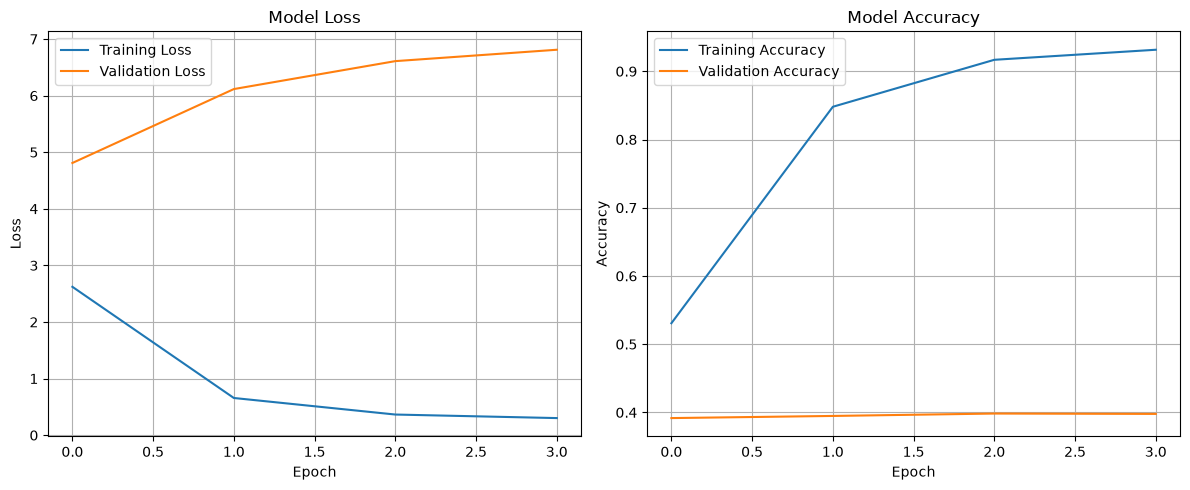

In [8]:
# Cell 7: Plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()


plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# Cell 8: Save the model
model.save('kalevala_model.keras')
print("Model saved as 'kalevala_model.keras'")

Model saved as 'kalevala_model.keras'


In [10]:
def generate_text(model, prompt, num_tokens=100, temperature=1.0):
    generated_ids = encode(prompt)     # prompt must be non-empty

    for _ in range(num_tokens):
        context = generated_ids[-seq_length:]
        n = len(context)
        x = np.array([context + [0] * (seq_length - n)])   # right-pad; causal mask hides it

        logits = model(x, training=False).numpy()[0, n - 1] / temperature
        probs = np.exp(logits - logits.max())
        probs /= probs.sum()
        generated_ids.append(int(np.random.choice(len(probs), p=probs)))

    return decode(generated_ids)

In [11]:
# Cell 10: Generate sample text
prompts = [
    "Vaka vanha Väinämöinen",
    "Mieleni minun tekevi",
    "Lemminkäinen",
    "Pohjan neito"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: Vaka vanha Väinämöinen
Vaka vanha Väinämöinen
itse virkkoi, noin nimesi:
"Multa Ahti veikkoseni!
Muistatko mitä mieluhke'imman
syytä syntynynnä,
ilman atunehen, kiurittamista!
Ei neittä ison kotona,
emon kaunon kartanolla.
"Kuules vielä, kuin sanelen,
vielä kerran toisen:
vielä järven rannat, pellon päähän,
annan marjanvartöni lähemmä, 

Prompt: Mieleni minun tekevi
Mieleni minun tekevi,
kirjokannen kiskontahan
noille Pohjolan pihoille,
unille miehelässä?'
"An tarkka hiihkoillehen,
emon koskilta tuikutella,
pulman tuulimma rannan tekoiset,
savu sakeammeni,
tuosta toisna kallitteli
kolmannesti poikaime
sakkiessa luona laulamalla,
kopissa Karjalassa!
"Onp' on katsettu Kolmasti,


Prompt: Lemminkäinen
Lemminkäinen
säkehinä säinensä sävien runo


Siitä lieto Lemminkäinen,
kerran kerta keske'ille,
maalle tappelmille vetehen,
ilman tuota purtta pukkui:
aivan tarkka tappeli venettä,
tyvät petäjät,
unuinen vaamokat vaja
kyynelesi liikahuisi
- pitkän mislan kansan,
kal kulkija kiuiksi 

In [ ]:
# Cell 11: Load model (if you're starting a new session)
# Uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('kalevala_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('kalevala_sp.model')

# Test generation
prompt = "Mieleni minun tekevi"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""